In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid")

In [58]:
# Membaca dataset dengan beberapa alternatif encoding
for encoding in ["utf-8", "cp1252", "latin1"]:
    try:
        df = pd.read_csv("health.csv", encoding=encoding)
        print("Dataset berhasil dibaca dengan encoding:", encoding)
        break
    except UnicodeDecodeError:
        continue
else:
    raise ValueError("Dataset gagal dibaca. Periksa file health.csv.")

print("Ukuran dataset:", df.shape)
display(df.head())

print("Jumlah baris duplikat:", df.duplicated().sum())

Dataset berhasil dibaca dengan encoding: cp1252
Ukuran dataset: (8423, 25)


,SV_TAXONOMY,TAXONOMY_NAME,RG_REFERENCE,RG_NAME,SV_REFERENCE,SV_NAME,SV_DESCRIPTION,SL_REFERENCE,LC_REFERENCE,PHONE_NUMBER,...,STREET_NUMBER,STREET_NAME,STREET_TYPE,STREET_DIRECTION,CITY,PROVINCE,POSTAL_CODE,LATITUDE,LONGITUDE,811_LINK
0,RF-3300,Individual Counselling,17636359,Urban Native Youth Association,17636360,Aboriginal Youth Safehouse,Provides short-term emergency shelter for both...,NaN,NaN,604-254-5147,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,http://www.healthlinkbc.ca/find/resource.asp?F...
1,RP-1400.8000-050,Adolescent/Youth Counselling,17636359,Urban Native Youth Association,17636360,Aboriginal Youth Safehouse,Provides short-term emergency shelter for both...,NaN,NaN,604-254-5147,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,http://www.healthlinkbc.ca/find/resource.asp?F...
2,RX-8450.7000,Residential Substance Use Disorder Treatment F...,17636359,Urban Native Youth Association,17636365,Young Bears Lodge,"Provides a 16 week, live-in, culturally-based ...",NaN,NaN,604-322-7577,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,http://www.healthlinkbc.ca/find/resource.asp?F...
3,RX-8450.8000,Substance Use Disorder Counselling,17636359,Urban Native Youth Association,17636366,Alcohol and Drug Counselling,Offers community-based substance use counselli...,17636367.0,17636362.0,604-254-7732,...,1618 E Hastings Street,NaN,NaN,NaN,Vancouver,BC,V5L 1S6,49.281279,-123.072101,http://www.healthlinkbc.ca/find/resource.asp?F...
4,RF-3300,Individual Counselling,17636359,Urban Native Youth Association,17636368,Clinical Counselling,Provides individual counselling to Indigenous ...,17636369.0,17636362.0,604-254-7732,...,1618 E Hastings Street,NaN,NaN,NaN,Vancouver,BC,V5L 1S6,49.281279,-123.072101,http://www.healthlinkbc.ca/find/resource.asp?F...


Jumlah baris duplikat: 0


In [59]:
print("Jumlah missing value setiap kolom:")
print(df.isnull().sum())

missing_summary = pd.DataFrame({
    "Jumlah Missing": df.isnull().sum(),
    "Persentase Missing (%)": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

display(
    missing_summary.sort_values(
        "Jumlah Missing",
        ascending=False
    )
)

Jumlah missing value setiap kolom:
SV_TAXONOMY                 0
TAXONOMY_NAME               0
RG_REFERENCE                0
RG_NAME                     0
SV_REFERENCE                0
SV_NAME                     0
SV_DESCRIPTION              0
SL_REFERENCE              542
LC_REFERENCE              542
PHONE_NUMBER             2056
WEBSITE                   335
EMAIL_ADDRESS            4990
WHEELCHAIR_ACCESSIBLE       0
LANGUAGE                 8104
HOURS                    3127
STREET_NUMBER             542
STREET_NAME              8423
STREET_TYPE              8423
STREET_DIRECTION         8423
CITY                      542
PROVINCE                  542
POSTAL_CODE               542
LATITUDE                  542
LONGITUDE                 542
811_LINK                    0
dtype: int64


,Jumlah Missing,Persentase Missing (%)
STREET_NAME,8423,100.00
STREET_TYPE,8423,100.00
STREET_DIRECTION,8423,100.00
LANGUAGE,8104,96.21
EMAIL_ADDRESS,4990,59.24
HOURS,3127,37.12
PHONE_NUMBER,2056,24.41
LC_REFERENCE,542,6.43
SL_REFERENCE,542,6.43
POSTAL_CODE,542,6.43


In [60]:
print("Statistik deskriptif kolom numerik:")
display(df.describe())

print("\nStatistik deskriptif seluruh kolom:")
display(df.describe(include="all").T)

Statistik deskriptif kolom numerik:


,RG_REFERENCE,SV_REFERENCE,SL_REFERENCE,LC_REFERENCE,STREET_NAME,STREET_TYPE,STREET_DIRECTION,LATITUDE,LONGITUDE
count,8.423000e+03,8.423000e+03,7.881000e+03,7.881000e+03,0.0,0.0,0.0,7881.000000,7881.000000
mean,1.877647e+07,2.341452e+07,3.275420e+07,2.165766e+07,NaN,NaN,NaN,50.322457,-122.257788
std,6.280194e+06,1.319700e+07,1.994887e+07,1.131553e+07,NaN,NaN,NaN,2.021606,2.939838
min,1.763636e+07,1.763636e+07,1.763637e+07,1.763636e+07,NaN,NaN,NaN,48.378506,-133.704315
25%,1.764186e+07,1.764311e+07,1.764462e+07,1.764313e+07,NaN,NaN,NaN,49.179698,-123.170316
50%,1.764654e+07,1.764942e+07,1.765742e+07,1.764706e+07,NaN,NaN,NaN,49.314395,-122.841887
75%,1.765214e+07,1.765858e+07,5.399624e+07,1.765639e+07,NaN,NaN,NaN,50.675245,-120.354025
max,7.049658e+07,7.088646e+07,7.088670e+07,7.088669e+07,NaN,NaN,NaN,59.923636,-114.892672



Statistik deskriptif seluruh kolom:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
SV_TAXONOMY,8423,126,YF-5000,910,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TAXONOMY_NAME,8423,126,Mental Illness/Emotional Disabilities,910,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RG_REFERENCE,8423.0,NaN,NaN,NaN,18776466.001662,6280194.136864,17636359.0,17641862.0,17646543.0,17652139.0,70496577.0
RG_NAME,8423,740,Interior Health Authority,1381,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SV_REFERENCE,8423.0,NaN,NaN,NaN,23414522.310341,13196995.227082,17636360.0,17643114.5,17649420.0,17658576.5,70886458.0
SV_NAME,8423,1657,Mental Health and Substance Use Services,489,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SV_DESCRIPTION,8423,2250,Provides a range of mental health assessment a...,360,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SL_REFERENCE,7881.0,NaN,NaN,NaN,32754201.700419,19948867.801663,17636367.0,17644621.0,17657420.0,53996243.0,70886704.0
LC_REFERENCE,7881.0,NaN,NaN,NaN,21657662.839741,11315530.127536,17636362.0,17643134.0,17647063.0,17656393.0,70886693.0
PHONE_NUMBER,6367,1816,604-431-7206,59,NaN,NaN,NaN,NaN,NaN,NaN,NaN


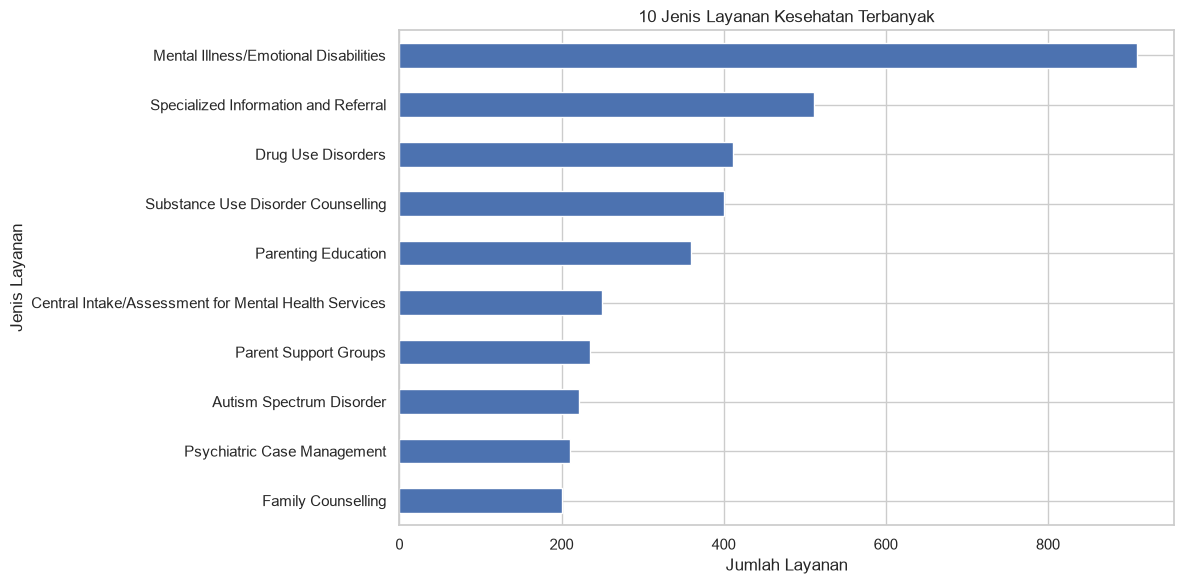

In [61]:
if "TAXONOMY_NAME" in df.columns:
    top_taxonomy = df["TAXONOMY_NAME"].value_counts().head(10)

    plt.figure(figsize=(12, 6))
    top_taxonomy.sort_values().plot(kind="barh")
    plt.title("10 Jenis Layanan Kesehatan Terbanyak")
    plt.xlabel("Jumlah Layanan")
    plt.ylabel("Jenis Layanan")
    plt.tight_layout()
    plt.show()

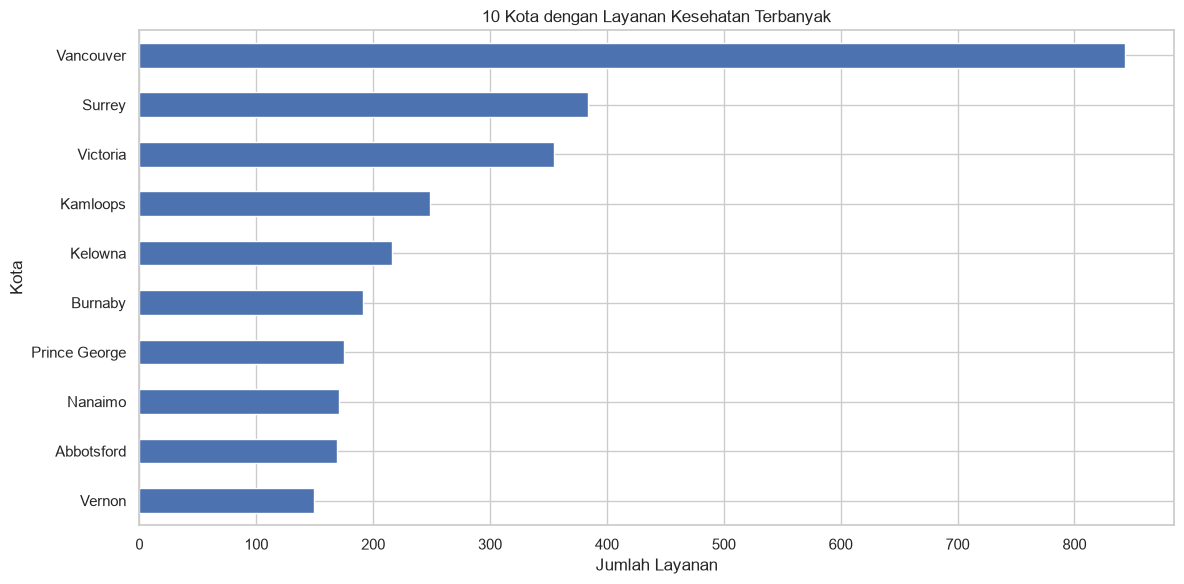

Jumlah layanan per kota:


,Jumlah Layanan
CITY,
Vancouver,843
Surrey,384
Victoria,355
Kamloops,249
Kelowna,216
Burnaby,191
Prince George,175
Nanaimo,171
Abbotsford,169


In [62]:
if "CITY" in df.columns:
    top_cities = df["CITY"].value_counts().head(10)

    plt.figure(figsize=(12, 6))
    top_cities.sort_values().plot(kind="barh")
    plt.title("10 Kota dengan Layanan Kesehatan Terbanyak")
    plt.xlabel("Jumlah Layanan")
    plt.ylabel("Kota")
    plt.tight_layout()
    plt.show()

    print("Jumlah layanan per kota:")
    display(top_cities.to_frame(name="Jumlah Layanan"))

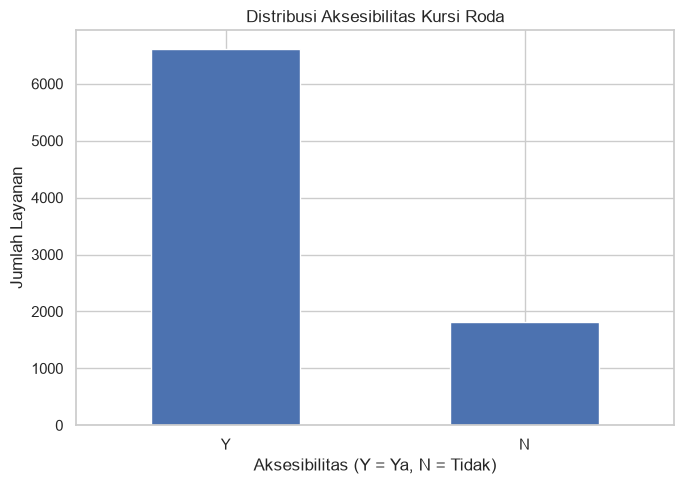

Jumlah setiap kategori aksesibilitas:


,Jumlah
WHEELCHAIR_ACCESSIBLE,
Y,6606
N,1817


In [63]:
if "WHEELCHAIR_ACCESSIBLE" in df.columns:
    accessibility_counts = (
        df["WHEELCHAIR_ACCESSIBLE"]
        .value_counts()
        .reindex(["Y", "N"], fill_value=0)
    )

    plt.figure(figsize=(7, 5))
    accessibility_counts.plot(kind="bar")
    plt.title("Distribusi Aksesibilitas Kursi Roda")
    plt.xlabel("Aksesibilitas (Y = Ya, N = Tidak)")
    plt.ylabel("Jumlah Layanan")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

    print("Jumlah setiap kategori aksesibilitas:")
    display(accessibility_counts.to_frame(name="Jumlah"))

Kolom numerik: ['RG_REFERENCE', 'SV_REFERENCE', 'SL_REFERENCE', 'LC_REFERENCE', 'STREET_NAME', 'STREET_TYPE', 'STREET_DIRECTION', 'LATITUDE', 'LONGITUDE']


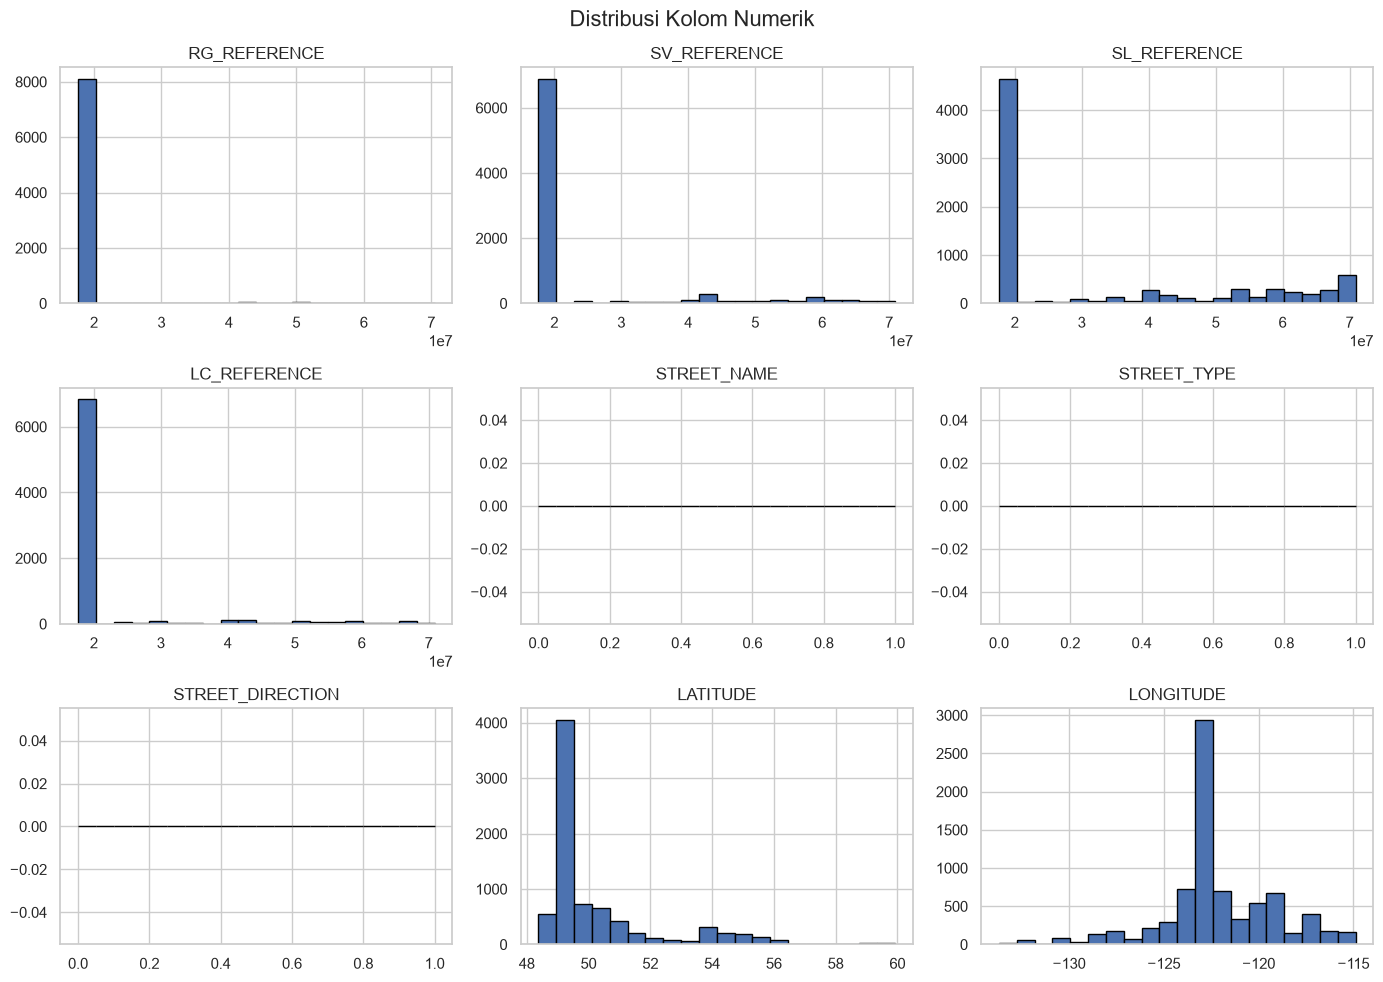

In [64]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

print("Kolom numerik:", numeric_cols)

if numeric_cols:
    df[numeric_cols].hist(
        figsize=(14, 10),
        bins=20,
        edgecolor="black"
    )
    plt.suptitle("Distribusi Kolom Numerik", fontsize=16)
    plt.tight_layout()
    plt.show()
else:
    print("Tidak ada kolom numerik untuk dibuat histogram.")

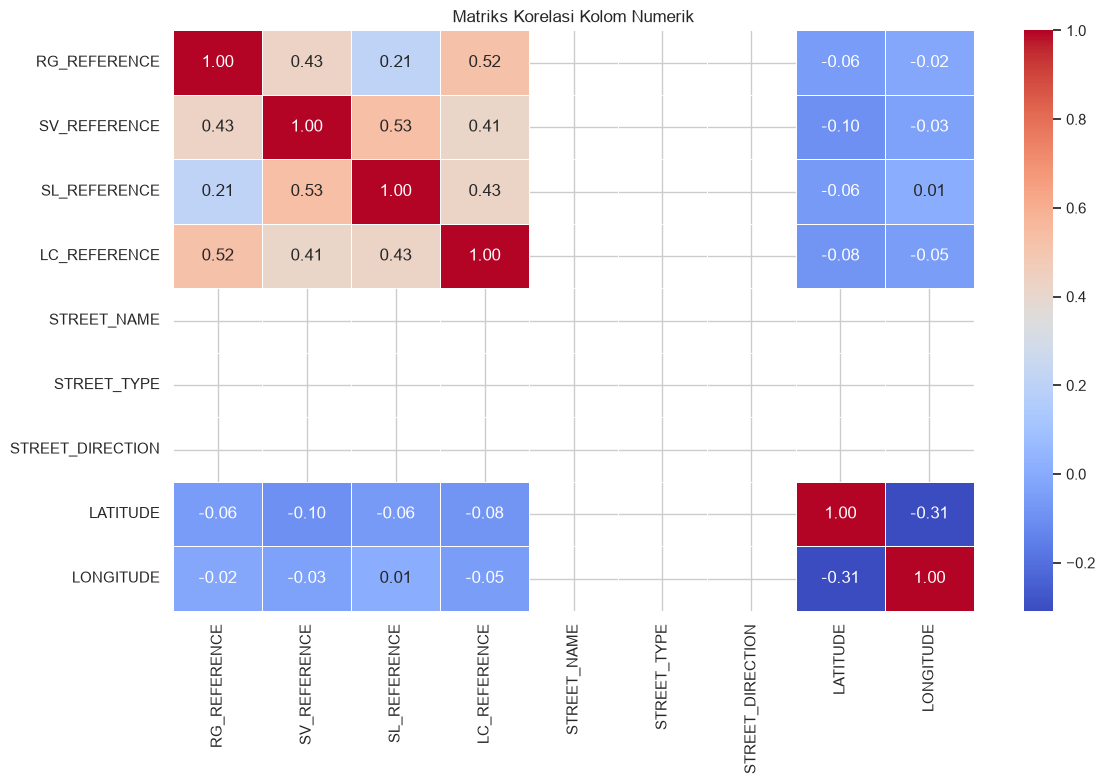

,RG_REFERENCE,SV_REFERENCE,SL_REFERENCE,LC_REFERENCE,STREET_NAME,STREET_TYPE,STREET_DIRECTION,LATITUDE,LONGITUDE
RG_REFERENCE,1.000000,0.428068,0.210612,0.520335,NaN,NaN,NaN,-0.056934,-0.016480
SV_REFERENCE,0.428068,1.000000,0.530426,0.413975,NaN,NaN,NaN,-0.097513,-0.032896
SL_REFERENCE,0.210612,0.530426,1.000000,0.425661,NaN,NaN,NaN,-0.059909,0.012865
LC_REFERENCE,0.520335,0.413975,0.425661,1.000000,NaN,NaN,NaN,-0.081384,-0.051144
STREET_NAME,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
STREET_TYPE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
STREET_DIRECTION,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LATITUDE,-0.056934,-0.097513,-0.059909,-0.081384,NaN,NaN,NaN,1.000000,-0.308375
LONGITUDE,-0.016480,-0.032896,0.012865,-0.051144,NaN,NaN,NaN,-0.308375,1.000000


In [65]:
numeric_data = df.select_dtypes(include=np.number)

if numeric_data.shape[1] >= 2:
    correlation_matrix = numeric_data.corr()

    plt.figure(figsize=(12, 8))
    sns.heatmap(
        correlation_matrix,
        annot=True,
        cmap="coolwarm",
        fmt=".2f",
        linewidths=0.5
    )
    plt.title("Matriks Korelasi Kolom Numerik")
    plt.tight_layout()
    plt.show()

    display(correlation_matrix)
else:
    print("Kolom numerik kurang dari dua, korelasi tidak dapat dihitung.")

In [66]:
required_columns = [
    "CITY",
    "TAXONOMY_NAME",
    "PROVINCE",
    "WHEELCHAIR_ACCESSIBLE"
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Kolom yang dibutuhkan tidak ditemukan: {missing_columns}"
    )

# Menyalin kolom yang diperlukan
df_ml = df[required_columns].copy()

# Membersihkan target
df_ml["WHEELCHAIR_ACCESSIBLE"] = (
    df_ml["WHEELCHAIR_ACCESSIBLE"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Hanya gunakan target Y atau N
df_ml = df_ml[
    df_ml["WHEELCHAIR_ACCESSIBLE"].isin(["Y", "N"])
].copy()

# Mengisi kategori kosong
for col in ["CITY", "TAXONOMY_NAME", "PROVINCE"]:
    df_ml[col] = df_ml[col].fillna("Unknown").astype(str)

# Encoding fitur kategori
encoders = {}

for col in ["CITY", "TAXONOMY_NAME", "PROVINCE"]:
    encoder = LabelEncoder()
    df_ml[col + "_enc"] = encoder.fit_transform(df_ml[col])
    encoders[col] = encoder

# Encoding target: N = 0 dan Y = 1
df_ml["TARGET"] = df_ml["WHEELCHAIR_ACCESSIBLE"].map({
    "N": 0,
    "Y": 1
})

feature_columns = [
    "CITY_enc",
    "TAXONOMY_NAME_enc",
    "PROVINCE_enc"
]

X = df_ml[feature_columns]
y = df_ml["TARGET"]

print("Jumlah data untuk pemodelan:", len(df_ml))
print("Jumlah fitur:", len(feature_columns))
print("\nDistribusi target:")
print(df_ml["WHEELCHAIR_ACCESSIBLE"].value_counts())

display(df_ml.head())

Jumlah data untuk pemodelan: 8423
Jumlah fitur: 3

Distribusi target:
WHEELCHAIR_ACCESSIBLE
Y    6606
N    1817
Name: count, dtype: Int64


,CITY,TAXONOMY_NAME,PROVINCE,WHEELCHAIR_ACCESSIBLE,CITY_enc,TAXONOMY_NAME_enc,PROVINCE_enc,TARGET
0,Unknown,Individual Counselling,Unknown,N,177,55,1,0
1,Unknown,Adolescent/Youth Counselling,Unknown,N,177,6,1,0
2,Unknown,Residential Substance Use Disorder Treatment F...,Unknown,N,177,98,1,0
3,Vancouver,Substance Use Disorder Counselling,BC,Y,179,106,0,1
4,Vancouver,Individual Counselling,BC,Y,179,55,0,1


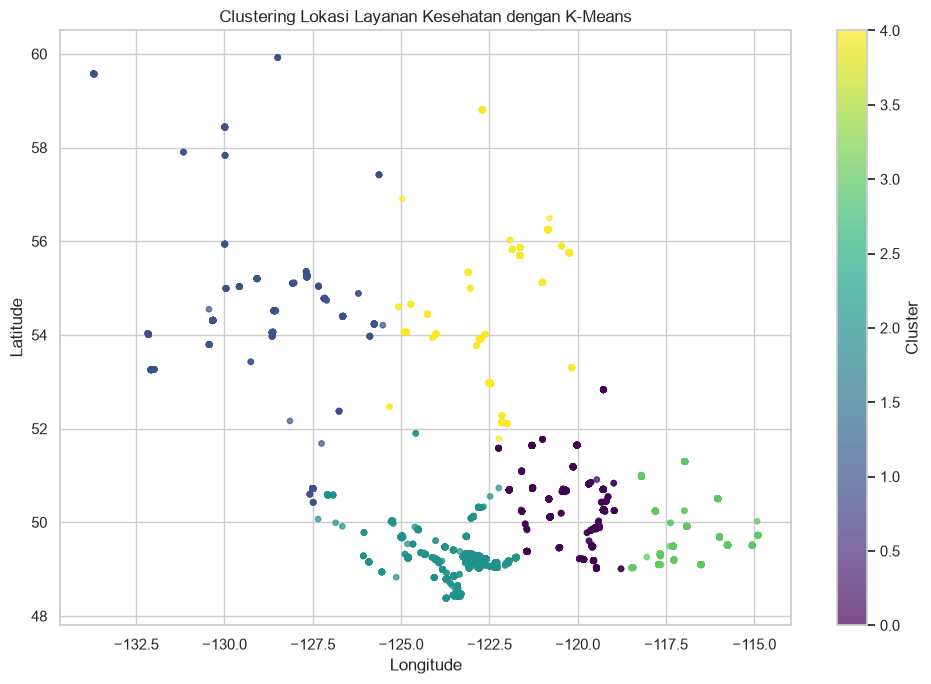

Jumlah data lokasi: 7881

Jumlah lokasi pada setiap cluster:


,Jumlah Lokasi
CLUSTER,
0,1487
1,583
2,4221
3,888
4,702


In [67]:
coordinate_columns = ["LATITUDE", "LONGITUDE"]

if all(col in df.columns for col in coordinate_columns):
    location_data = df[coordinate_columns].copy()

    location_data["LATITUDE"] = pd.to_numeric(
        location_data["LATITUDE"], errors="coerce"
    )
    location_data["LONGITUDE"] = pd.to_numeric(
        location_data["LONGITUDE"], errors="coerce"
    )

    location_data = location_data.replace(
        [np.inf, -np.inf], np.nan
    ).dropna()

    # Memastikan jumlah cluster tidak melebihi jumlah data
    n_clusters = min(5, len(location_data))

    if n_clusters >= 1:
        kmeans = KMeans(
            n_clusters=n_clusters,
            random_state=42,
            n_init=10
        )

        location_data["CLUSTER"] = kmeans.fit_predict(
            location_data[coordinate_columns]
        )

        plt.figure(figsize=(10, 7))
        scatter = plt.scatter(
            location_data["LONGITUDE"],
            location_data["LATITUDE"],
            c=location_data["CLUSTER"],
            cmap="viridis",
            s=15,
            alpha=0.7
        )

        plt.title("Clustering Lokasi Layanan Kesehatan dengan K-Means")
        plt.xlabel("Longitude")
        plt.ylabel("Latitude")
        plt.colorbar(scatter, label="Cluster")
        plt.tight_layout()
        plt.show()

        print("Jumlah data lokasi:", len(location_data))
        print("\nJumlah lokasi pada setiap cluster:")
        display(
            location_data["CLUSTER"]
            .value_counts()
            .sort_index()
            .to_frame(name="Jumlah Lokasi")
        )
else:
    print("Kolom LATITUDE dan LONGITUDE tidak tersedia.")

In [68]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

print("\nDistribusi target training:")
print(y_train.value_counts())

print("\nDistribusi target testing:")
print(y_test.value_counts())

Jumlah data training: 6738
Jumlah data testing: 1685

Distribusi target training:
TARGET
1    5284
0    1454
Name: count, dtype: int64

Distribusi target testing:
TARGET
1    1322
0     363
Name: count, dtype: int64


In [69]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Model Random Forest berhasil dilatih.")

Model Random Forest berhasil dilatih.


In [70]:
y_pred = rf_model.predict(X_test)

prediction_results = pd.DataFrame({
    "Aktual": y_test,
    "Prediksi": y_pred
})

# Mengubah kode target menjadi label yang mudah dibaca
prediction_results["Aktual_Label"] = (
    prediction_results["Aktual"].map({0: "N", 1: "Y"})
)
prediction_results["Prediksi_Label"] = (
    prediction_results["Prediksi"].map({0: "N", 1: "Y"})
)

display(prediction_results.head(10))

,Aktual,Prediksi,Aktual_Label,Prediksi_Label
7146,1,1,Y,Y
1100,0,1,N,Y
671,0,0,N,N
2559,1,1,Y,Y
5984,1,1,Y,Y
1722,1,0,Y,N
7768,0,1,N,Y
1499,1,1,Y,Y
7684,0,0,N,N
5977,1,1,Y,Y


In [71]:
accuracy = accuracy_score(y_test, y_pred)

print(f"Akurasi model: {accuracy * 100:.2f}%")
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["N - Tidak aksesibel", "Y - Aksesibel"],
        zero_division=0
    )
)

Akurasi model: 73.95%

Classification Report:
                     precision    recall  f1-score   support

N - Tidak aksesibel       0.42      0.56      0.48       363
      Y - Aksesibel       0.87      0.79      0.83      1322

           accuracy                           0.74      1685
          macro avg       0.64      0.67      0.65      1685
       weighted avg       0.77      0.74      0.75      1685



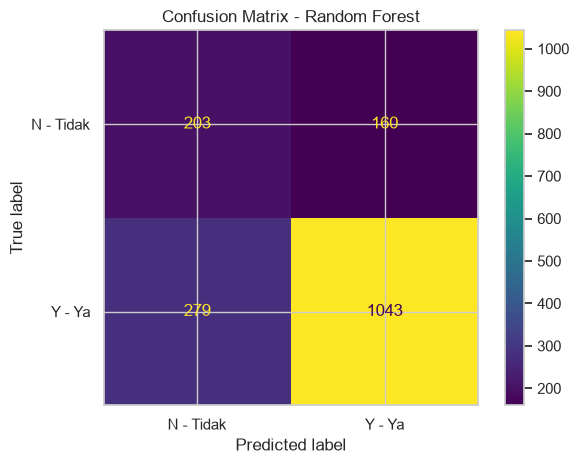

Confusion matrix:
[[ 203  160]
 [ 279 1043]]


In [72]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["N - Tidak", "Y - Ya"]
)

disp.plot(values_format="d")
plt.title("Confusion Matrix - Random Forest")
plt.tight_layout()
plt.show()

print("Confusion matrix:")
print(cm)

,Fitur,Importance
0,CITY_enc,0.529897
1,TAXONOMY_NAME_enc,0.322987
2,PROVINCE_enc,0.147116


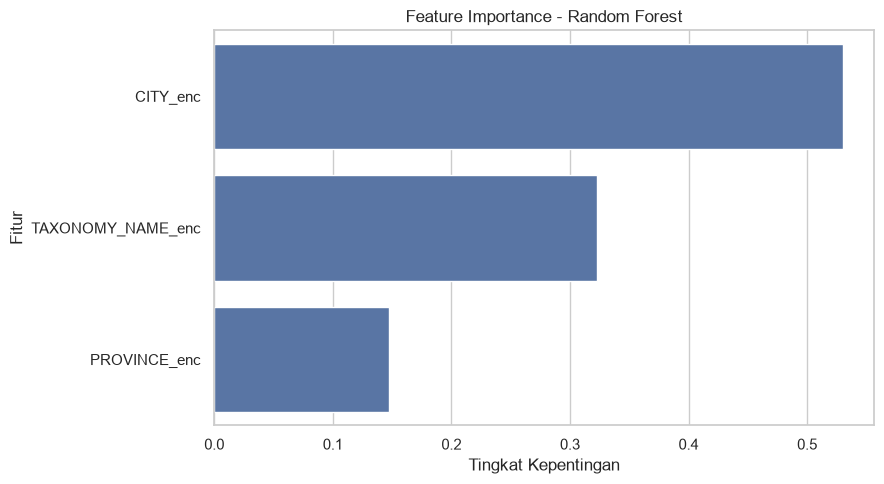

In [73]:
feature_importance = pd.DataFrame({
    "Fitur": feature_columns,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(feature_importance)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Fitur"
)
plt.title("Feature Importance - Random Forest")
plt.xlabel("Tingkat Kepentingan")
plt.ylabel("Fitur")
plt.tight_layout()
plt.show()

In [74]:
model_bundle = {
    "model": rf_model,
    "encoders": encoders,
    "feature_columns": feature_columns,
    "target_mapping": {"N": 0, "Y": 1}
}

with open("random_forest_health.pkl", "wb") as file:
    pickle.dump(model_bundle, file)

print("Model berhasil disimpan sebagai random_forest_health.pkl")

Model berhasil disimpan sebagai random_forest_health.pkl


In [75]:
with open("random_forest_health.pkl", "rb") as file:
    loaded_bundle = pickle.load(file)

loaded_model = loaded_bundle["model"]

print("Model berhasil dimuat kembali.")

Model berhasil dimuat kembali.


In [76]:
def predict_accessibility(city, taxonomy_name, province):
    new_data = pd.DataFrame([{
        "CITY": str(city),
        "TAXONOMY_NAME": str(taxonomy_name),
        "PROVINCE": str(province)
    }])

    encoded_values = {}

    for col in ["CITY", "TAXONOMY_NAME", "PROVINCE"]:
        encoder = loaded_bundle["encoders"][col]
        value = new_data.loc[0, col]

        if value not in encoder.classes_:
            raise ValueError(
                f"Kategori '{value}' tidak dikenal pada kolom {col}. "
                "Gunakan kategori yang tersedia dalam dataset."
            )

        encoded_values[col + "_enc"] = encoder.transform([value])[0]

    input_data = pd.DataFrame(
        [encoded_values],
        columns=loaded_bundle["feature_columns"]
    )

    prediction = loaded_model.predict(input_data)[0]
    probabilities = loaded_model.predict_proba(input_data)[0]

    label = "Y - Aksesibel" if prediction == 1 else "N - Tidak aksesibel"

    print("Hasil prediksi:", label)
    print(f"Probabilitas kelas N: {probabilities[0] * 100:.2f}%")
    print(f"Probabilitas kelas Y: {probabilities[1] * 100:.2f}%")

    return label

In [77]:
# Mengambil contoh kategori yang tersedia dalam dataset
contoh_city = encoders["CITY"].classes_[0]
contoh_taxonomy = encoders["TAXONOMY_NAME"].classes_[0]
contoh_province = encoders["PROVINCE"].classes_[0]

predict_accessibility(
    contoh_city,
    contoh_taxonomy,
    contoh_province
)

Hasil prediksi: Y - Aksesibel
Probabilitas kelas N: 5.43%
Probabilitas kelas Y: 94.57%


'Y - Aksesibel'

In [78]:
print("=" * 55)
print("KESIMPULAN ANALISIS DATA HEALTH")
print("=" * 55)

print(f"Jumlah data setelah cleaning: {len(df)}")
print(f"Jumlah fitur model: {len(feature_columns)}")
print(f"Jumlah data training: {len(X_train)}")
print(f"Jumlah data testing: {len(X_test)}")
print(f"Akurasi Random Forest: {accuracy * 100:.2f}%")

print("\nFitur dengan importance tertinggi:")
print(feature_importance.iloc[0]["Fitur"])

print("\nDistribusi target:")
print(df_ml["WHEELCHAIR_ACCESSIBLE"].value_counts())

print("\nAnalisis selesai.")

KESIMPULAN ANALISIS DATA HEALTH
Jumlah data setelah cleaning: 8423
Jumlah fitur model: 3
Jumlah data training: 6738
Jumlah data testing: 1685
Akurasi Random Forest: 73.95%

Fitur dengan importance tertinggi:
CITY_enc

Distribusi target:
WHEELCHAIR_ACCESSIBLE
Y    6606
N    1817
Name: count, dtype: Int64

Analisis selesai.
